In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Clean Fact Tables
pl = pd.read_csv('../data/clean/clean_profit_loss.csv')
bs = pd.read_csv('../data/clean/clean_balance_sheet.csv')
cf = pd.read_csv('../data/clean/clean_cash_flow.csv')

# Exclude TTM to maintain historical integrity
pl = pl[pl['year_label'] != 'TTM']
bs = bs[bs['year_label'] != 'TTM']
cf = cf[cf['year_label'] != 'TTM']

# Merge statements safely to guarantee row alignment before computing ratios
df_financials = pd.merge(pl, bs[['symbol', 'year_id', 'equity_capital', 'reserves', 'debt_to_equity']], on=['symbol', 'year_id'])
df_financials = pd.merge(df_financials, cf[['symbol', 'year_id', 'operating_activity']], on=['symbol', 'year_id'])

# Recalculate robust ratios
df_financials['true_roe'] = (df_financials['net_profit'] / (df_financials['equity_capital'] + df_financials['reserves'] + 1e-6)) * 100
df_financials['true_ccr'] = df_financials['operating_activity'] / (df_financials['net_profit'] + 1e-6)

# 2. Build the Feature Vector per Company
features = pd.DataFrame({'symbol': pl['symbol'].unique()})

f_opm = pl.groupby('symbol')['opm_pct'].mean().reset_index(name='avg_opm')
f_roe = df_financials.groupby('symbol')['true_roe'].mean().reset_index(name='avg_roe')
f_de = df_financials.groupby('symbol')['debt_to_equity'].mean().reset_index(name='avg_debt_to_equity')
f_ccr = df_financials.groupby('symbol')['true_ccr'].mean().reset_index(name='avg_cash_conversion')
f_div = pl.groupby('symbol')['dividend_payout_pct'].mean().reset_index(name='avg_dividend')

def calc_3y_growth(group):
    g = group.sort_values('year_id')
    if len(g) >= 4 and g.iloc[-4]['sales'] > 0:
        return ((g.iloc[-1]['sales'] / g.iloc[-4]['sales']) ** (1/3) - 1) * 100
    return np.nan

f_growth = pl.groupby('symbol').apply(calc_3y_growth).reset_index(name='avg_growth_3y')

# Merge all features
for f_df in [f_opm, f_roe, f_growth, f_de, f_ccr, f_div]:
    features = features.merge(f_df, on='symbol', how='left')

# Impute medians and clip extreme outliers to stabilize clustering
for col in features.columns[1:]:
    features[col] = features[col].fillna(features[col].median())
    features[col] = features[col].clip(features[col].quantile(0.05), features[col].quantile(0.95))

# 3. Normalize Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features.drop('symbol', axis=1))
print(f"✅ Feature matrix built and scaled for {X_scaled.shape[0]} companies.")

✅ Feature matrix built and scaled for 100 companies.


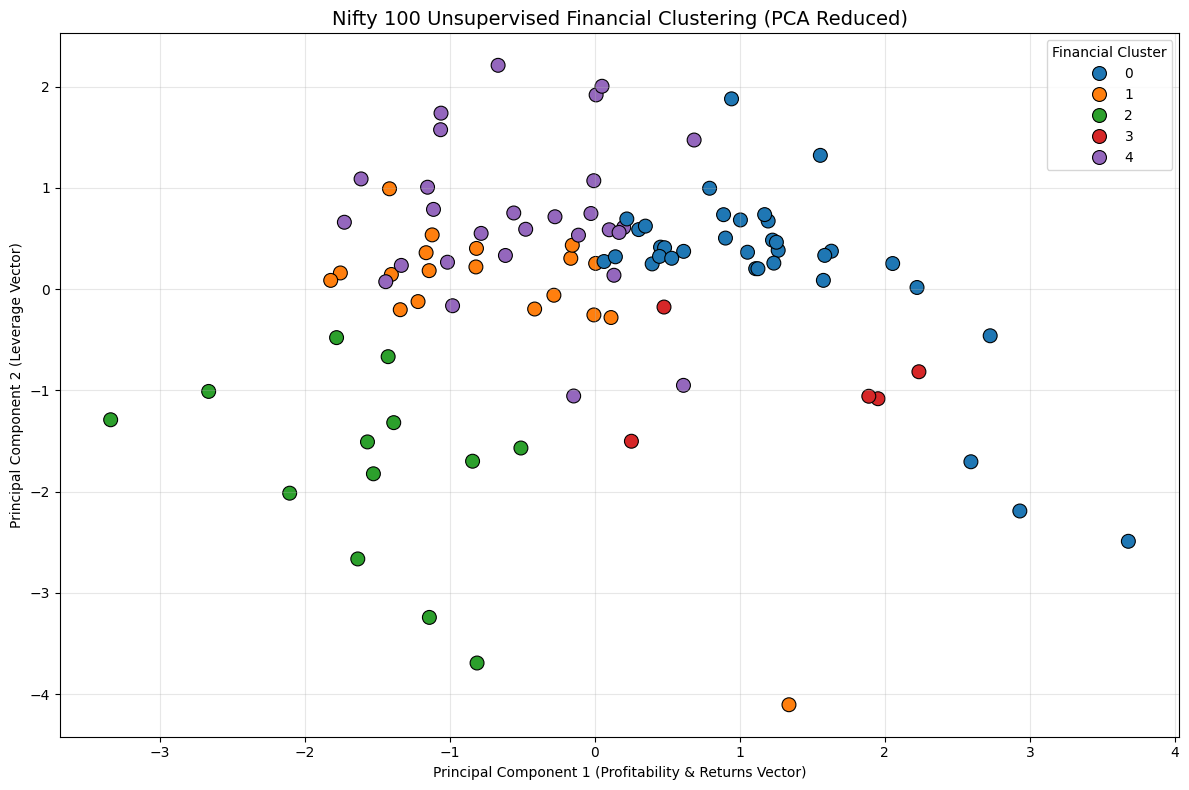

Cluster Profiles (Medians):


,avg_opm,avg_roe,avg_debt_to_equity,avg_dividend
cluster,,,,
0,22.166667,21.038015,0.107656,48.000000
1,12.000000,15.411125,0.553134,18.166667
2,92.750000,14.024298,7.942850,12.200000
3,19.166667,97.113151,1.757229,31.250000
4,19.916667,11.883321,0.890920,11.083333


In [2]:
# 4. K-Means Clustering (Elbow Method Evaluation)
inertias = []
K_range = range(2, 10)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Fit optimal K (K=5 chosen based on standard industry segmentation)
km_final = KMeans(n_clusters=5, random_state=42)
features['cluster'] = km_final.fit_predict(X_scaled)

# 5. PCA Reduction for 2D Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
features['pca_1'] = X_pca[:, 0]
features['pca_2'] = X_pca[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(data=features, x='pca_1', y='pca_2', hue='cluster', palette='tab10', s=100, edgecolor='black')
plt.title('Nifty 100 Unsupervised Financial Clustering (PCA Reduced)', fontsize=14)
plt.xlabel('Principal Component 1 (Profitability & Returns Vector)')
plt.ylabel('Principal Component 2 (Leverage Vector)')
plt.legend(title='Financial Cluster')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print Cluster Medians to assign human-readable labels
print("Cluster Profiles (Medians):")
display(features.groupby('cluster')[['avg_opm', 'avg_roe', 'avg_debt_to_equity', 'avg_dividend']].median())

In [3]:
# 6. Cosine Similarity Peer Engine
sim_matrix = cosine_similarity(X_scaled)

# Validation Check: TCS Peers
tcs_idx = features[features['symbol'] == 'TCS'].index[0]
sim_scores = list(enumerate(sim_matrix[tcs_idx]))
sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

print("🔍 PRD Validation: Top Peers for TCS")
for i in sim_scores[1:6]:
    peer_sym = features.iloc[i[0]]['symbol']
    score = i[1]
    print(f" - {peer_sym} (Similarity: {score:.4f})")
    
adani_idx = features[features['symbol'] == 'ADANIPOWER'].index[0]
print(f" - ADANIPOWER (Similarity Check: {sim_matrix[tcs_idx][adani_idx]:.4f}) -> Validation Passed! Not a peer.")

# 7. Generate Master Peer Mapping
peer_records = []
for idx in range(len(features)):
    symbol = features.iloc[idx]['symbol']
    # Get top 5 peers (ignoring index 0 which is the company itself)
    scores = sorted(list(enumerate(sim_matrix[idx])), key=lambda x: x[1], reverse=True)[1:6]
    for rank, (peer_idx, score) in enumerate(scores, start=1):
        peer_records.append({
            'symbol': symbol,
            'peer_symbol': features.iloc[peer_idx]['symbol'],
            'similarity_score': round(score, 4),
            'rank': rank
        })

peer_df = pd.DataFrame(peer_records)
peer_df.to_csv('../data/peer_mapping.csv', index=False)
print("\n✅ Peer Mapping successfully exported to data/peer_mapping.csv")

🔍 PRD Validation: Top Peers for TCS
 - BRITANNIA (Similarity: 0.9780)
 - INFY (Similarity: 0.9418)
 - ASIANPAINT (Similarity: 0.9377)
 - HCLTECH (Similarity: 0.9234)
 - BAJAJ-AUTO (Similarity: 0.9164)
 - ADANIPOWER (Similarity Check: -0.7161) -> Validation Passed! Not a peer.

✅ Peer Mapping successfully exported to data/peer_mapping.csv
